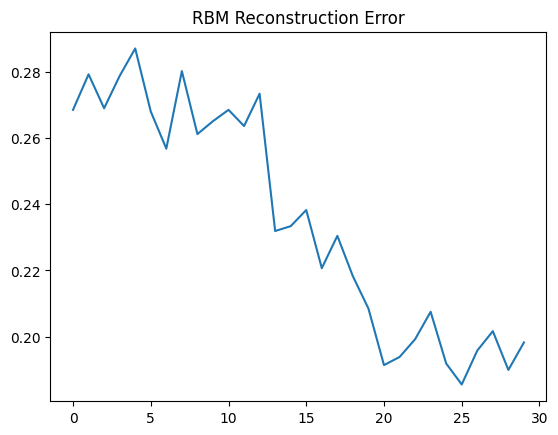

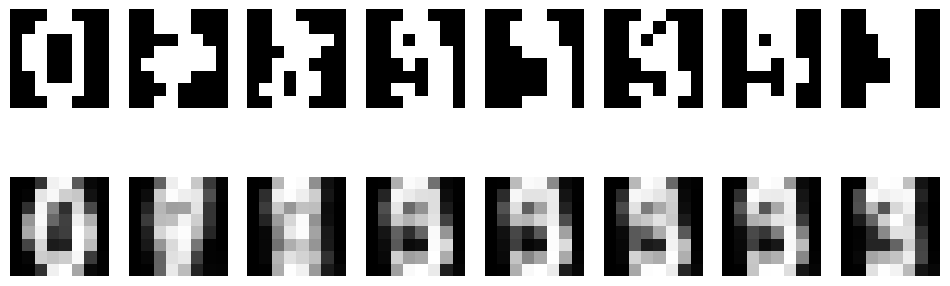

Energy Example: -40.115373003451396


In [15]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

np.random.seed(42)

X = (load_digits().data / 16 > 0.3).astype("float32")

nv = 64
nh = 32

W = 0.01*np.random.randn(nv, nh)
a = np.zeros(nv)
b = np.zeros(nh)

def sigmoid(x):
    return 1/(1+np.exp(-np.clip(x, -30, 30)))

def sample(p):
    return (np.random.rand(*p.shape) < p).astype("float32")

def energy(v, h):
    return -v@a - h@b - v@W@h

errors = []

for epoch in range(30):

    np.random.shuffle(X)

    for start in range(0, len(X)-32, 32):

        v = X[start:start+32]

        ph = sigmoid(v@W+b)
        h = sample(ph)

        vk = sample(sigmoid(h@W.T+a))
        phk = sigmoid(vk@W+b)

        W += 0.03*(v.T@ph-vk.T@phk)/len(v)
        a += 0.03*np.mean(v-vk, axis=0)
        b += 0.03*np.mean(ph-phk, axis=0)

    errors.append(np.mean((v-vk)**2))

plt.plot(errors)
plt.title("RBM Reconstruction Error")
plt.show()

fig, ax = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    ax[0,i].imshow(X[i].reshape(8,8), cmap="gray")
    ax[1,i].imshow(
        sigmoid(sigmoid(X[i:i+1]@W+b)@W.T+a).reshape(8,8),
        cmap="gray"
    )

    ax[0,i].axis("off")
    ax[1,i].axis("off")

plt.show()

print("Energy Example:", energy(X[0], sample(sigmoid(X[0]@W+b))))
